<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Clustering with K-Means - Solution

---

### About
Understand what unsupervised learning is, when to apply clustering, and perform a k-means clustering, evaluating cluster quality using Silhouette Coefficient and Inertia.

### Learning Objectives
- Know the difference between supervised and unsupervised learning.
- Understand when to use clustering.
- Perform a k-Means clustering analysis.
- Evaluate clusters for fit with Silhouette Coefficient and Inertia.

### Notebook Guide
- Imports
- Make Data
- Metrics for Assessing Clusters
- Using the elbow method to choose k
- Bonus Exercise: Old Faithful
- Conclusions and Takeaways

# Imports

In [1]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib

matplotlib.style.use('ggplot')

# Make Data
Let's make some more blobs to test K-Means on.

In [2]:
# Let's make some more blobs to test K-Means on
data, color = make_blobs(n_samples=100, random_state=42, centers=3, cluster_std=1.5)

df = pd.DataFrame(data, columns=["x1", "x2"])
df.head()

,x1,x2
0,-8.149818,-9.152380
1,5.860155,0.126873
2,-3.213409,9.828126
3,6.744070,-0.129607
4,-6.342946,-6.038933


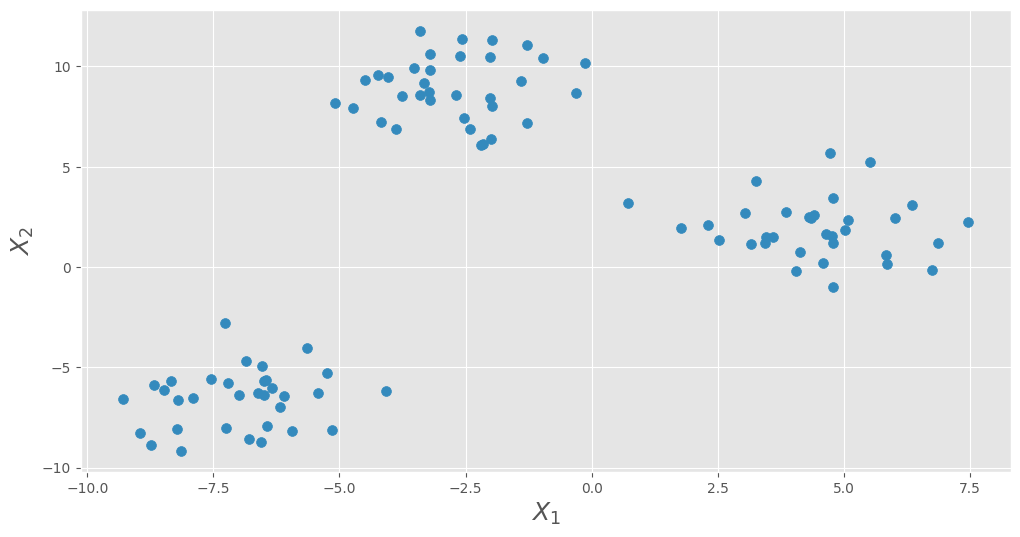

In [3]:
# Take a look at the data using a scatterplot
df.plot(kind="scatter", x="x1", y="x2", figsize=(12,6), s=50)
plt.xlabel("$X_1$", fontsize=18)
plt.ylabel("$X_2$", fontsize=18);

In [4]:
# Define X
X = df[['x1', 'x2']]

In [5]:
# There's a VERY important step before fitting our K-Means Model. Any ideas?
sc = StandardScaler()
X_scaled = sc.fit_transform(X)

In [6]:
# Fit a K-means clustering model
km = KMeans(n_clusters=3, random_state=42)
km.fit(X_scaled)

KMeans(n_clusters=3, random_state=42)

## What did we discover?

### I. Cluster Predictions

In [7]:
# Option 1: Class attribute

km.labels_

array([1, 2, 0, 2, 1, 2, 0, 2, 2, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1,
       1, 0, 0, 0, 2, 1, 1, 1, 1, 2, 2, 1, 0, 0, 0, 0, 2, 2, 1, 0, 2, 0,
       0, 2, 1, 1, 1, 2, 2, 2, 0, 1, 1, 1, 0, 0, 2, 0, 1, 2, 1, 2, 1, 1,
       2, 1, 2, 2, 2, 1, 1, 0, 2, 1, 2, 1, 2, 2, 0, 2, 0, 1, 0, 0, 0, 2,
       0, 2, 2, 2, 0, 2, 0, 0, 0, 2, 1, 0], dtype=int32)

In [8]:
# Option 2: Predict

km.predict(X_scaled)

array([1, 2, 0, 2, 1, 2, 0, 2, 2, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1,
       1, 0, 0, 0, 2, 1, 1, 1, 1, 2, 2, 1, 0, 0, 0, 0, 2, 2, 1, 0, 2, 0,
       0, 2, 1, 1, 1, 2, 2, 2, 0, 1, 1, 1, 0, 0, 2, 0, 1, 2, 1, 2, 1, 1,
       2, 1, 2, 2, 2, 1, 1, 0, 2, 1, 2, 1, 2, 2, 0, 2, 0, 1, 0, 0, 0, 2,
       0, 2, 2, 2, 0, 2, 0, 0, 0, 2, 1, 0], dtype=int32)

In [9]:
# Attach predicted cluster to original points

df['cluster'] = km.labels_
df.head()

,x1,x2,cluster
0,-8.149818,-9.152380,1
1,5.860155,0.126873,2
2,-3.213409,9.828126,0
3,6.744070,-0.129607,2
4,-6.342946,-6.038933,1


### II. Centroids

In [10]:
# Option 1: Using groupby

df.groupby('cluster').mean()

,x1,x2
cluster,,
0,-2.747107,8.896498
1,-6.987751,-6.574270
2,4.429326,1.921795


In [11]:
# Option 2: (Preferred method) Using cluster_centers_

km.cluster_centers_

# But wait... why does this not match the one above?!

array([[-0.19912024,  1.13805994],
       [-1.07070258, -1.23896837],
       [ 1.27585677,  0.06642177]])

In [12]:
# Remember, we scaled this! We need to "unscale".

centroids = sc.inverse_transform(km.cluster_centers_)
centroids

array([[-2.74710707,  8.89649797],
       [-6.98775083, -6.57427024],
       [ 4.42932559,  1.92179535]])

## Visually Verifying Cluster Labels

In [13]:
# Create Centroid DataFrame
centroids = pd.DataFrame(
    centroids,
    columns=["x1", "x2"]
)
centroids

,x1,x2
0,-2.747107,8.896498
1,-6.987751,-6.574270
2,4.429326,1.921795


<Figure size 1000x800 with 0 Axes>

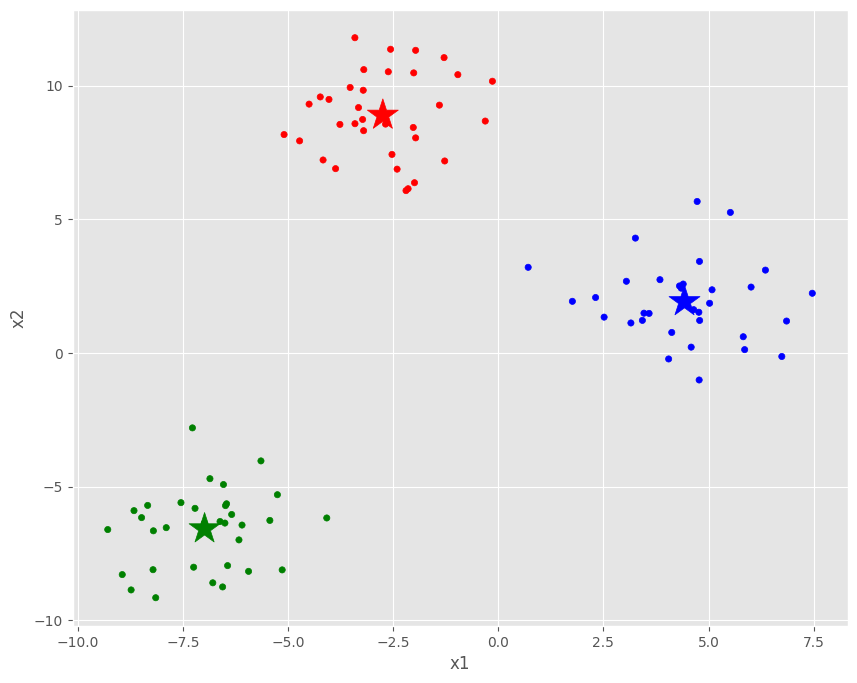

In [14]:
# Create Scatterplot!

# Figsize
plt.figure(figsize=(10,8))

# Map colors for different clusters
colors = ["red", "green", "blue"]
df['color'] = df['cluster'].map(lambda p: colors[p])

# Plot points
ax = df.plot(    
    kind="scatter", 
    x="x1", y="x2",
    figsize=(10,8),
    c = df['color']
)

# Plot Centroids
centroids.plot(
    kind="scatter", 
    x="x1", y="x2", 
    marker="*", c=["r", "g", "b"], s=550, ax=ax
);

---

To the slides!

---

# Metrics for Assessing Clusters
---
## Inertia

Sum of squared differences between each point in a cluster and that cluster's centroid.

How dense is each cluster? 


- low inertia = dense cluster
- ranges from 0 to very high values


$$ \sum_{j=0}^{n} (x_j - \mu_i)^2 $$

where $\mu_i$ is a cluster centroid



`.inertia_` is an attribute of a fitted sklearn's kmeans object

#### Lower inertia is better! Though be cautious with adding too many clusters.

#### Get the inertia

In [15]:
km.inertia_

12.264727255529845

---
## Silhouette Score

Tells you how much closer data points are to their own clusters than to the nearest neighbor cluster.

How far apart are the clusters?
- ranges from -1 to 1
- high silhouette score means the clusters are well separated



### $s_i = \frac{b_i - a_i}{max\{a_i, b_i\}}$

Where:
- $a_i$ = Cohesion: Mean distance of points within a cluster from each other.
- $b_i$ = Separation: Mean distance from point $x_i$ to all points in the next nearest cluster.

Use scikit-learn: `metrics.silhouette_score(X_scaled, labels)`.

#### Higher silhouette score is better!


#### Compute the silhouette score 

In [16]:
from sklearn.metrics import silhouette_score

In [17]:
silhouette_score(X_scaled, km.labels_)

0.7723797723428811

# Using the elbow method to choose _k_
---

The [elbow method](https://en.wikipedia.org/wiki/Elbow_method_(clustering)) is one possible method to help narrow in on the ideal value of **K**. 

### Choose the number of clusters where the next cluster doesn't significantly improve performance. 

#### Let's use the `.interia_` method as our evaluation metric

In [18]:
inertia_list = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia_list.append(kmeans.inertia_)
    
inertia_list

[200.00000000000003,
 67.9287466927128,
 12.264727255529845,
 10.821344959475987,
 9.244715891917576,
 7.520926489333977,
 6.375889625855397,
 5.663940108251783,
 4.952865696711444,
 4.38466405346858]

#### Analyze the above

- Do you see the **"elbow"**?

- What's the best value for _k_?



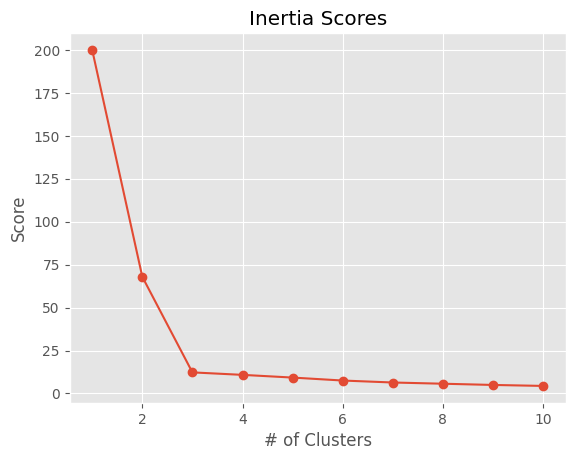

In [19]:
plt.plot(range(1, 11), inertia_list, marker='o')
plt.xlabel('# of Clusters')
plt.ylabel('Score')
plt.title('Inertia Scores');


#### Now let's make a plot with the silhouette score

## Remember: Higher is Better for Silhouette Score!

In [20]:
silhouette_list = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    silhouette_list.append(silhouette_score(X_scaled, kmeans.labels_))
silhouette_list

[0.6461767583224244,
 0.7723797723428811,
 0.615225851180092,
 0.4666788967952153,
 0.3345305546438127,
 0.3611157233146528,
 0.34334071654624926,
 0.3357487067273421,
 0.3425928318288836]

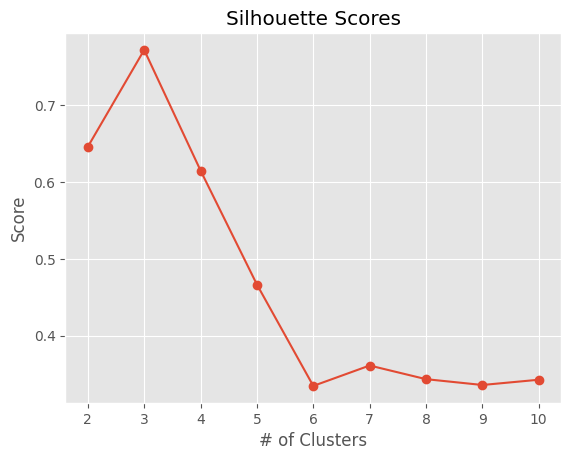

In [21]:
plt.plot(range(2, 11), silhouette_list, marker='o')
plt.xlabel('# of Clusters')
plt.ylabel('Score')
plt.title('Silhouette Scores');

#### What _k_ should we choose?

3!

# Bonus Exercise 🏋️‍♂️🏋️‍♀️ : Old Faithful
---
The classic Old Faithful dataset describes the durations of eruptions and the amount of waiting time since the last eruption for the Old Faithful geyser. Plot this data. Do you think this data could benefit from clustering? How many clusters are there?

In [23]:
df = pd.read_csv("../data/geyser.csv")
df.head()

,duration,waiting
0,3.600,79
1,1.800,54
2,3.333,74
3,2.283,62
4,4.533,85


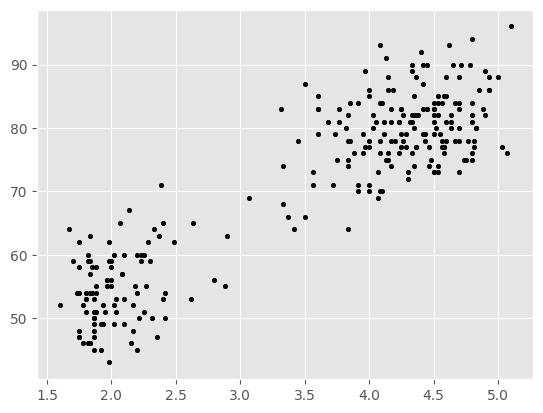

In [24]:
plt.scatter(df['duration'], df['waiting'], c="black", s=10);

In [25]:
# Define X
X = df[['duration', 'waiting']]

In [26]:
# There's a VERY important step before fitting our K-Means Model. Any ideas?
sc = StandardScaler()
X_scaled = sc.fit_transform(X)

In [27]:
# Fit a K-means clustering model
km = KMeans(n_clusters=2, random_state=42)
km.fit(X_scaled)

KMeans(n_clusters=2, random_state=42)

In [28]:
df['cluster'] = km.labels_
df.head()

,duration,waiting,cluster
0,3.600,79,0
1,1.800,54,1
2,3.333,74,0
3,2.283,62,1
4,4.533,85,0


In [29]:
# Create Centroid DataFrame
centroids = pd.DataFrame(
    sc.inverse_transform(km.cluster_centers_),
    columns=["duration", "waiting"]
)
centroids

,duration,waiting
0,4.296328,80.080460
1,2.052204,54.591837


<Figure size 1000x800 with 0 Axes>

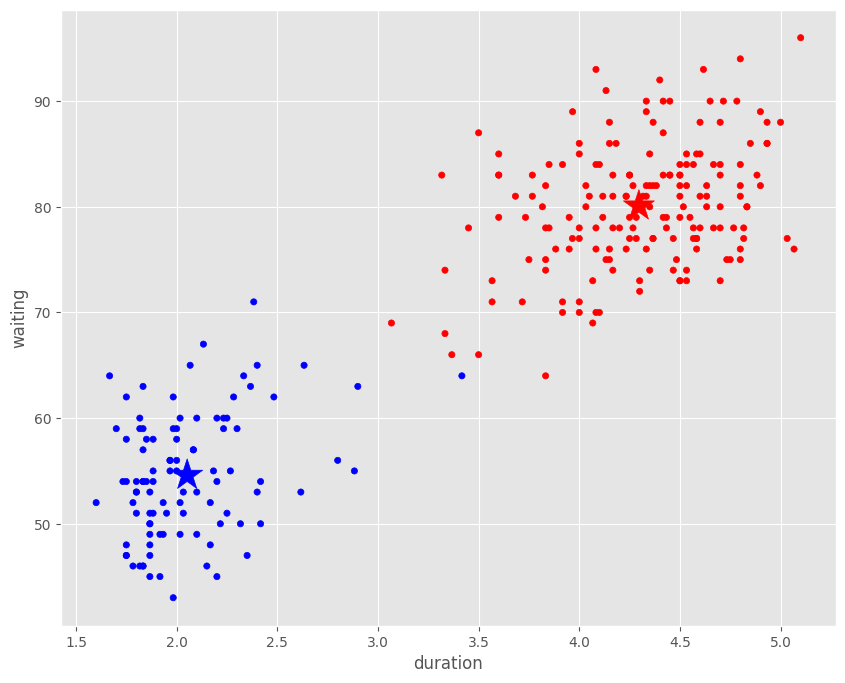

In [30]:
# Create Scatterplot!

# Figsize
plt.figure(figsize=(10,8))

# Map colors for different clusters
colors = ["red", "blue"]
df['color'] = df['cluster'].map(lambda p: colors[p])

# Plot points
ax = df.plot(    
    kind="scatter", 
    x="duration", y="waiting",
    figsize=(10,8),
    c = df['color']
)

# Plot Centroids
centroids.plot(
    kind="scatter", 
    x="duration", y="waiting", 
    marker="*", c=["r", "b"], s=550, ax=ax
);

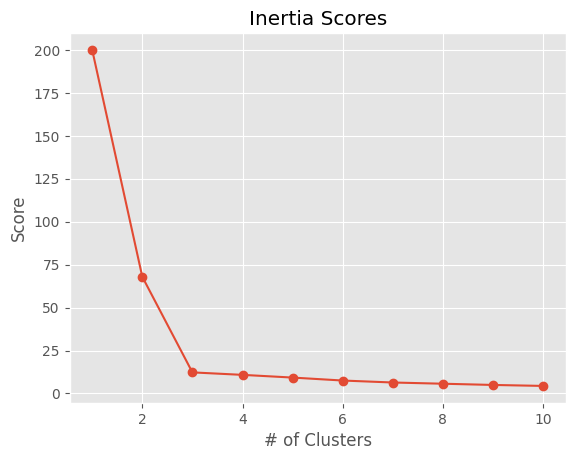

In [31]:
plt.plot(range(1, 11), inertia_list, marker='o')
plt.xlabel('# of Clusters')
plt.ylabel('Score')
plt.title('Inertia Scores');

In [32]:
silhouette_list = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    silhouette_list.append(silhouette_score(X_scaled, kmeans.labels_))
silhouette_list

[0.7451774401207985,
 0.4862768070583076,
 0.45709063162077557,
 0.3628136336605467,
 0.39195723856418185,
 0.36011380915466923,
 0.3616038673396824,
 0.3581345447093625,
 0.35638322509918674]

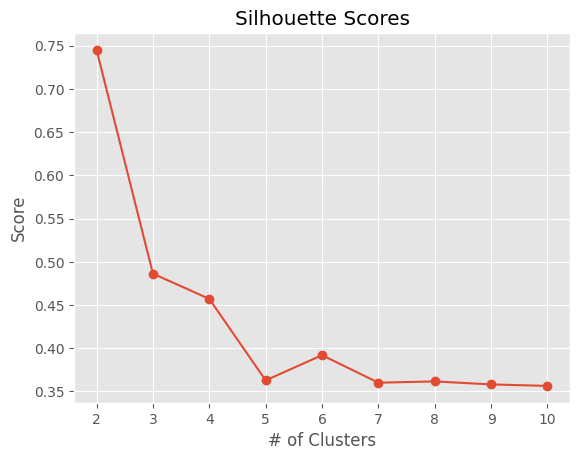

In [33]:
plt.plot(range(2, 11), silhouette_list, marker='o')
plt.xlabel('# of Clusters')
plt.ylabel('Score')
plt.title('Silhouette Scores');

### How many clusters should be used?

2!

# Conclusions and Takeaways
---

Remember that different starting points may give you different clusters. ⚠️ You won't necessarily get an optimal set of clusters!    

You've learned about when and how to use the unsupervised learning clustering algorithm _k-means_. You saw how to save your cluster labels in a DataFrame. You learned several way to evaluate the best number of clusters. 

### Questions...

- What's the main difference between supervised learning and unsupervised learning?
- Why use clustering?
- What does k-means clustering do?
- What does silhouette score measure?

## More Unsupervised learning in the wild

> 1. www.storyblocks.com -- "More Like This" 
> 1. www.amazon.com
> 1. Faces in your photos 

<img src= 'https://support.apple.com/library/content/dam/edam/applecare/images/en_US/iOS/ios15-iphone12-pro-photos-people-album-favorites.png' style='height:500px' />


## Further reading

- The [scikit-learn documentation](http://scikit-learn.org/stable/modules/clustering.html) has a great summary of many other clustering algorithms.
- This [PyData talk](https://www.youtube.com/watch?v=Mf6MqIS2ql4) is good overview of clustering, different algorithms, and how to think about the quality of your clusters.